In [1]:
import numpy as np
import matplotlib
import math
from matplotlib import axes
from matplotlib import tri
from matplotlib import pyplot
from matplotlib import patches as mplp
from matplotlib import lines as mlines
#from scipy.stats import kde
%matplotlib inline

In [2]:
ObservablePlusData = np.transpose(np.asarray(np.genfromtxt('ObservablePlus_FundCStarData.csv',delimiter=',')))

In [3]:
ObservablePlusData[3][1]

1.7e-11

In [4]:
def ErrorClean_1 (Data_Set): # A function to clear all data with unreliable values in Mdot or L
    CuttingArray = []
    i = 0
    Cleaned_Set = np.transpose(Data_Set)
    while i<len(Data_Set[3]):
        if Data_Set[3][i]/Data_Set[2][i] > 1: # If the relative error is greater than one for the dust mass-loss rate
            CuttingArray.append(i)
        elif Data_Set[9][i]/Data_Set[8][i] > 1: # If the relative error is greater than one for the luminosity
            CuttingArray.append(i)
        i += 1
    Cleaned_Set = np.delete(Cleaned_Set,CuttingArray,axis=0)
    print ('Entries Removed:',len(CuttingArray))
    print ('Stars Remaining:', len(Cleaned_Set))
    return np.transpose(Cleaned_Set)
        

In [5]:
ObservablePlusData = ErrorClean_1 (ObservablePlusData)

Entries Removed: 5
Stars Remaining: 2064


In [6]:
def InitialFinalClean (Data_Set):
    CuttingArray = []
    i = 0
    Cleaned_Set = np.transpose(Data_Set)
    M0Max = 0.6
    MfMin = 0.452+0.073*M0Max
    while i<len(Data_Set[3]):
        if Data_Set[18][i] < MfMin: # If the final mass is less than that predicted for lowest initial mass AGB stars
            CuttingArray.append(i)
        i += 1
    Cleaned_Set = np.delete(Cleaned_Set,CuttingArray,axis=0)
    print ('Entries Removed:',len(CuttingArray))
    print ('Stars Remaining:', len(Cleaned_Set))
    return np.transpose(Cleaned_Set)

In [7]:
ObservablePlusData = InitialFinalClean (ObservablePlusData)

Entries Removed: 22
Stars Remaining: 2042


In [8]:
DustMdotData = ObservablePlusData[2]
DustMdotData_Error = ObservablePlusData[3]
Total_from_Dust_Mdot_Data = np.log10(ObservablePlusData[5]) # Log Mdot as calculated from the dust mass loss rate
Total_from_Dust_Mdot_Data_error = np.log10(ObservablePlusData[6]) # Log Mdot as calculated from the dust mass loss rate
MData = ObservablePlusData[18] # Mass data as calculated from evolutionary track and PMR relation
LData = ObservablePlusData[8] # Luminosity data
LDataError = ObservablePlusData[9]
LSmearedData = ObservablePlusData[11] # Luminosity data smeared using errors in data
PData = ObservablePlusData[13]
RData = ObservablePlusData[19]
TeffData = ObservablePlusData[12]
CalcTeffData = ObservablePlusData[20]
CalcTeff_fromSmearData = ObservablePlusData[21]
CalcColor = ObservablePlusData[17]
CalcMag3_6 = ObservablePlusData[14]
Chi2Data = ObservablePlusData[22]

In [9]:
Total_from_Dust_Mdot_Data_error

array([-7.13402341, -7.43505341, -6.3037745 , ..., -6.85258897,
       -7.55155898, -7.62410965])

In [10]:
OriginalMethodConstantsArray = np.asarray([[2, -13.1468, 0.129896],[5, -23.867, 3.32474],[10, -41.734, 8.64948],[15, -59.601, 13.9742],[20, -77.468, 19.299]]) 
# A matrix that holds the values of b, a' = log A', and c from the orginal determining method

In [11]:
def calc_b_and_c_ratio (input_array):
    Array = []
    i = 0
    while i < len(input_array):
        print('Current set:', input_array[i])
        b = input_array[i][0]
        c = input_array[i][2]
        Ratio = b/(c+1)
        Array.append(Ratio)
        i +=1
    return np.asarray(Array)

In [12]:
calc_b_and_c_ratio (OriginalMethodConstantsArray)

Current set: [  2.       -13.1468     0.129896]
Current set: [  5.      -23.867     3.32474]
Current set: [ 10.      -41.734     8.64948]
Current set: [ 15.     -59.601   13.9742]
Current set: [ 20.    -77.468  19.299]


array([1.77007441, 1.15613887, 1.03632527, 1.00172296, 0.98527021])

In [13]:
adoubleprimeArray=np.transpose(np.asarray([[-13.134,-23.3704,-40.431,-57.4916,-74.5522],[-13.1419,-23.8547,-41.7094,-59.5641,-77.4188],[-13.1513,-24.1158,-42.3899,-60.664,-78.9381],[-13.1616,-24.3425,-42.9773,-61.612,-80.2468],[-13.1774,-24.6349,-43.7307,-62.8266,-81.9224],[-13.1927,-24.8848,-44.3717,-63.8585,-83.3454]]))
# An array of values found for a'' found years ago. Rows are for a value of b (2, 5, 10, 15, or 20) and columns are different M0 (0.7, 1.0, 1.2, 1.4, 1.7, 2.0)


In [14]:
def CalculateAPrimeNewMethod (input_array):
    i = 0
    aprime_array = []
    average_aprime_array = []
    bArray = np.asarray([2,5,10,15,20])
    M0_array = np.asarray([0.7,1,1.2,1.4,1.7,2.0])
    while i <len (input_array):
        k = 0
        while k < len(M0_array):
            aprime = adoubleprimeArray[i][k] + ((bArray[i]/0.7)-1)*np.log10(M0_array[k])
            aprime_array.append(aprime)
            k += 1
        average_aprime = np.mean(aprime_array)
        average_aprime_array.append(average_aprime)
        i += 1
    return np.asarray(average_aprime_array)

In [15]:
CalculateAPrimeNewMethod (adoubleprimeArray)

array([-12.97351855, -18.27890917, -25.94224564, -34.19506439,
       -42.6836794 ])

In [16]:
def CalculateMdot (aprime,b,c,L, M): # Takes arrays of aprime, b, c, L, and M to calculate the Mdot for a set of stars
    i = 0
    logMdotArray = []
    while i < len(b):
        logMdot = aprime[i] + b[i]*np.log10(L) - c[i]*np.log10(M) 
        logMdotArray.append(logMdot)
        i += 1
        
    return np.asarray(logMdotArray)

In [17]:
np.log10(LData[1])
MData[1]
((-3.4153*15)-6.76)+15*np.log10(LData[1])-(1.51*15)*np.log10(MData[1])

-5.747443873816896

In [18]:
# We are assuming Mdot = A L^b M^-c
def CalculateMdotWillsonMethod (b,L, M): # Takes a value for an array of values for b and the work done by Lee Anne to calculate log A', c, and then Mdot for a star using log A', b, c, L, and M
    logAprimeS0 = -3.4153*b-6.76 # The value of log A' when S=0 (M<1.175) in Iben R(L,M,Z,alpha) relation
    logAprimeS1 = -3.4154*b-6.76# The value of log A' when S=1 (M>1.175) in Iben R(L,M,Z,alpha) relation
    cS0 = 1.059*b # The value of c when S=0 (M<1.175) in Iben R(L,M,Z,alpha) relation
    cS1 = 1.51*b# The value of c when S=1 (M>1.175) in Iben R(L,M,Z,alpha) relation
    bindex = 0
    logMdots = []
    logMdotArray = []
    while bindex < len(b):
        i = 0
        logMdots = []
        while i < len(M):
            if M[i] <1.175:
                logMdot = logAprimeS0[bindex] + b[bindex]*np.log10(L[i]) - cS0[bindex]*np.log10(M[i]) 
                logMdots.append(logMdot)
            else:
                logMdot = logAprimeS1[bindex] + b[bindex]*np.log10(L[i]) - cS1[bindex]*np.log10(M[i])
                logMdots.append(logMdot)
            i += 1
        logMdotArray.append(logMdots)
        bindex += 1
    return np.asarray(logMdotArray)

In [19]:
b_array = np.asarray([2,5,10,15,20])
Old_aprime_array = np.transpose(OriginalMethodConstantsArray)[1]
Old_c_array = np.transpose(OriginalMethodConstantsArray)[2]
new_aprime_array = CalculateAPrimeNewMethod (adoubleprimeArray)
new_c_array = ((b_array)/0.7)-1

In [20]:
Old_c_array

array([ 0.129896,  3.32474 ,  8.64948 , 13.9742  , 19.299   ])

In [21]:
new_c_array

array([ 1.85714286,  6.14285714, 13.28571429, 20.42857143, 27.57142857])

In [22]:
MdotsOldMethod=CalculateMdot(Old_aprime_array,b_array,Old_c_array,LData,MData)
MdotsNewMethod=CalculateMdot(new_aprime_array,b_array,new_c_array,LData,MData)
MdotsWillsonMethod = CalculateMdotWillsonMethod(b_array,LData,MData)
MdotsOldMethodSmeared=CalculateMdot(Old_aprime_array,b_array,Old_c_array,LSmearedData,MData)
MdotsNewMethodSmeared=CalculateMdot(new_aprime_array,b_array,new_c_array,LSmearedData,MData)
MdotsWillsonMethodSmeared = CalculateMdotWillsonMethod(b_array,LSmearedData,MData)

In [23]:
MdotsWillsonMethod

array([[-6.52445392, -6.62519252, -6.40306341, ..., -6.60551427,
        -6.73035346, -6.92694608],
       [-6.17113479, -6.42298129, -5.86765852, ..., -6.37378567,
        -6.68588366, -7.17736519],
       [-5.58226959, -6.08596258, -4.97531703, ..., -5.98757135,
        -6.61176732, -7.59473039],
       [-4.99340438, -5.74894387, -4.08297555, ..., -5.60135702,
        -6.53765098, -8.01209558],
       [-4.40453917, -5.41192517, -3.19063407, ..., -5.2151427 ,
        -6.46353464, -8.42946078]])

In [24]:
histbins = 30 # Set how many bins we want
histogram_marker = ','
histogram_linestyle = '-'
color_list = ['#000000','#e69f00','#56b4e9','#009e73','#f0e442', '#0072b2', '#d55e00', '#cc79a7']
mDotLimits = [-10,-5]
labelsize = 10 # Control the size of labels on plots, to easily switch between presentation plots and article plots
titlesize = 16 # Control the size of titles on plots, to easily switch between presentation plots and article plots

def calc_Bin_center(binedges):
    i = 0
    binCenters = []
    for i in range(0,len(binedges)-1):
        binCenter = (binedges[i]+binedges[i+1])/2
        binCenters.append(binCenter)
    return binCenters

def mdot_hist_plot_stack (input_array, combination, save_dir, name, img_type): # Takes an input array (np array input_array), a declaration of what the exponent is (int b),
    # where the plot should be saved (str save_dir), the name of the file (str name), and image type (str img_type)
    num_input = len(input_array)
    mdot_hist = pyplot.figure()
    
    index = 0
    CountsAllB = list()
    NormalizedCount = list()
    AllxPos = list()
    AllyError = list()
    label_set = ('b=2','b=5','b=10','b=15','b=20')
    while index < num_input: # repeat for every input array
        # Now, use this check and the input data to create a histogram
        Hist=pyplot.hist(input_array[index],label=label_set[index],bins=histbins,range=(mDotLimits),histtype=u'step')
        mdot_hist.clf()
        CountsAllB.append(np.asarray(Hist[0])) # Append counts to an array to hold all of the counts for various b that we can iterate over
        # Calculate the upper and lower error bounds on the counts
        #print (Hist[0])
        index += 1
    mdot_hist.clf() # Clear all those histograms so we can do something cleaner with the data
    
    # Now, plot all of that histogram data as some line plots
    BinCenters=calc_Bin_center(Hist[1]) # Edges of bins should match for all histograms
    index = 0 # Reset the index so it can be used again
    while index < num_input: # repeat for every input array
        plotLabel = label_set[index]
        #TotalCount = np.sum(CountsAllB[index])
        #NormalizedCount.append(CountsAllB[index]/TotalCount)
        # First, do a polynomial fit for the histogram of a given b
        #Polyfit = np.polyfit(BinCenters,NormalizedCount[index],degreeVar,full=True)
        #Coefficients = Polyfit[0]
        #Residuals = Polyfit[1]
        # Second, create an array of p(x) for the calculated polynomial
        #polynomial_values = create_plottable_polynomial(Coefficients,BinCenters)
        # Third, set all bins with a true non-observation to zero
        #polynomial_values = piecewise_fit (polynomial_values, CountsAllB[index])
        
        pyplot.plot(BinCenters,CountsAllB[index],label = plotLabel,marker = histogram_marker, linestyle = histogram_linestyle, color = color_list[index+1])
        #AllyError.append(yerror)
        #pyplot.errorbar(AllxPos[index],polynomial_values, yerr=yerror, xerr=None, capsize = capsizeVar, linestyle=histogram_linestyle, color = color_list[index+1])
        index += 1
    # Set the limits of the plot (again)
    pyplot.xlim(mDotLimits)

    ObsvHist = pyplot.hist(Total_from_Dust_Mdot_Data, histbins,range=(mDotLimits), stacked = True, color=color_list[0],histtype=u'stepfilled', label=r'$\mathrm{\dot{M}\, from\, Dust}$')
    #ObsvPolyfit=np.polyfit(BinCenters,ObsvHist[0],10,full = True)
    #ObsvCoeff = ObsvPolyfit[0]
    #polynomial_values = create_plottable_polynomial(ObsvCoeff,BinCenters)
    #polynomial_values = piecewise_fit (polynomial_values, ObsvHist[0])
    #pyplot.plot(BinCenters,polynomial_values,linestyle=histogram_linestyle,marker="*",label="Obsv. Best Fit", color = color_list[-2])
    #pyplot.vlines(BinCenters,0,polynomial_values,colors=color_list[-2],linestyle=vlinesLinestyle)
    # Create a legend
    pyplot.legend(loc='best',ncol=1)  
    
    MdotxlabelText = pyplot.xlabel(r'$\log \dot{M}\,(\mathrm{M_{\odot}/yr)}$')
    MdotxlabelText.set_fontsize(labelsize) 
    MdotylabelText = pyplot.ylabel(r'$\mathrm{Number\,of\,Stars}$')
    MdotylabelText.set_fontsize(labelsize) 
    
    MdotTitle = pyplot.title(r'$\mathrm{Mass\,Loss\,Rate}$'+combination)
    MdotTitle.set_fontsize(titlesize)
    pyplot.grid(True)
    
    mdot_hist.show()
    corrected_name = name.replace('_','')
    mdot_hist.savefig(save_dir + corrected_name + '.'+ img_type,format=img_type)
    pyplot.close(mdot_hist)
    print ('Plot '+corrected_name+'.'+img_type+' created in '+save_dir+'.') 

In [25]:
directory = 'MdotHistograms/OvertoneCRich/'

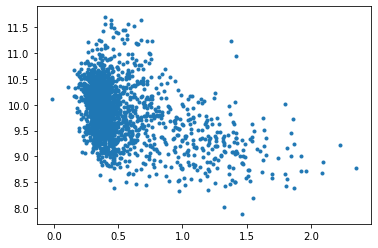

In [26]:
pyplot.scatter(CalcColor,CalcMag3_6,marker='.')

(array([  1.,   0.,  12.,  11.,  22.,  67.,  94.,  75., 132., 347., 363.,
        154., 214., 120.,  89.,  53.,  54.,  25.,  30.,  42.,  20.,  34.,
         39.,  21.,   6.,  10.,   4.,   0.,   2.,   1.]),
 array([-7.67427626, -7.57398379, -7.47369133, -7.37339886, -7.2731064 ,
        -7.17281393, -7.07252147, -6.97222901, -6.87193654, -6.77164408,
        -6.67135161, -6.57105915, -6.47076669, -6.37047422, -6.27018176,
        -6.16988929, -6.06959683, -5.96930437, -5.8690119 , -5.76871944,
        -5.66842697, -5.56813451, -5.46784204, -5.36754958, -5.26725712,
        -5.16696465, -5.06667219, -4.96637972, -4.86608726, -4.7657948 ,
        -4.66550233]),
 <a list of 30 Patch objects>)

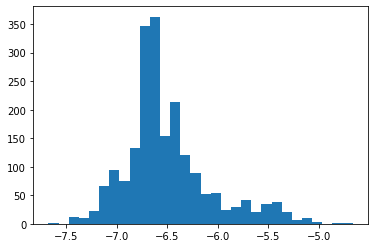

In [27]:
pyplot.hist(Total_from_Dust_Mdot_Data,bins=30)

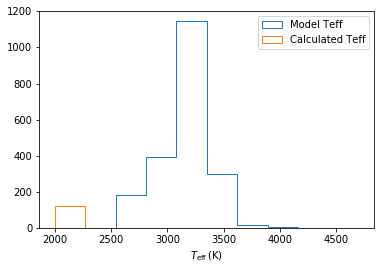

In [28]:
teff_hist = pyplot.figure()
matplotlib.pyplot.hist(TeffData, bins=10,range=[2000,4700],histtype='step',label="Model Teff")
matplotlib.pyplot.hist(CalcTeffData, bins=10,range=[2000,4700],histtype='step',label="Calculated Teff")
pyplot.legend(loc='best',ncol=1)  
MdotxlabelText = pyplot.xlabel(r'$T_{\mathrm{eff}}\,(\mathrm{K})}$')
MdotxlabelText.set_fontsize(labelsize) 
teff_hist.savefig(directory + "Teff_Histogram" + '.'+ "pdf",format='pdf')

In [29]:
#mdot_hist_plot_stack (input_array, combination, save_dir, name, img_type)
mDotLimits = [-10,-5]
mdot_hist_plot_stack(MdotsOldMethod,'ITZ',directory,'MdotOldMethod','pdf')
mdot_hist_plot_stack(MdotsWillsonMethod,'ITZ',directory,'MdotWillsonMethod','pdf')
mdot_hist_plot_stack(MdotsOldMethodSmeared,'ITZ',directory,'MdotOldMethodSmeared','pdf')
mdot_hist_plot_stack(MdotsWillsonMethodSmeared,'ITZ',directory,'MdotWillsonMethodSmeared','pdf')

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:80: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.


Plot MdotOldMethod.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:80: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.


Plot MdotWillsonMethod.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:80: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.


Plot MdotOldMethodSmeared.pdf created in MdotHistograms/OvertoneCRich/.
Plot MdotWillsonMethodSmeared.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:80: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.


In [30]:
mDotLimits = [-7.5,-5]
mdot_hist_plot_stack(MdotsOldMethod,'ITZ',directory,'MdotOldMethod_crit_zone','pdf')
mdot_hist_plot_stack(MdotsWillsonMethod,'ITZ',directory,'MdotWillsonMethod_crit_zone','pdf')
mdot_hist_plot_stack(MdotsOldMethodSmeared,'ITZ',directory,'MdotOldMethodSmeared_crit_zone','pdf')
mdot_hist_plot_stack(MdotsWillsonMethodSmeared,'ITZ',directory,'MdotWillsonMethodSmeared_crit_zone','pdf')

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:80: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.


Plot MdotOldMethodcritzone.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:80: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.


Plot MdotWillsonMethodcritzone.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:80: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.


Plot MdotOldMethodSmearedcritzone.pdf created in MdotHistograms/OvertoneCRich/.
Plot MdotWillsonMethodSmearedcritzone.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:80: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.


In [31]:
def PlotYvsX (x_array,y_array,x_label,y_label,save_dir, name, img_type):
    plot = pyplot.figure()
    pyplot.plot (x_array,y_array,linestyle="None",marker=".",markersize = 2) 
    
    xlabelText = pyplot.xlabel(x_label)
    xlabelText.set_fontsize(labelsize) 
    ylabelText = pyplot.ylabel(y_label)
    ylabelText.set_fontsize(labelsize) 
    
    plot.show()
    corrected_name = name.replace('_','')
    plot.savefig(save_dir + corrected_name + '.'+ img_type,format=img_type)
    pyplot.close(plot)
    print ('Plot '+corrected_name+'.'+img_type+' created in '+save_dir+'.') 

In [32]:
PlotYvsX (np.log10(LSmearedData),Total_from_Dust_Mdot_Data,"logL","logMdot",directory,'LvMdotOldMethodSmeared_Z003','pdf')
PlotYvsX (MData,Total_from_Dust_Mdot_Data,"M","logMdot",directory,'MvMdotOldMethodSmeared_Z003','pdf')
PlotYvsX (np.log10(PData),Total_from_Dust_Mdot_Data,"logP","logMdot",directory,'PvMdotOldMethodSmeared_Z003','pdf')

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:10: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  # Remove the CWD from sys.path while we load stuff.
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:10: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  # Remove the CWD from sys.path while we load stuff.


Plot LvMdotOldMethodSmearedZ003.pdf created in MdotHistograms/OvertoneCRich/.
Plot MvMdotOldMethodSmearedZ003.pdf created in MdotHistograms/OvertoneCRich/.
Plot PvMdotOldMethodSmearedZ003.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:10: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  # Remove the CWD from sys.path while we load stuff.


In [33]:
def PlotYvsX_with_range (x_array,y_array,xrange,yrange,x_label,y_label,save_dir, name, img_type):
    plot = pyplot.figure()
    pyplot.plot (x_array,y_array,linestyle="None",marker=".",markersize = 2) 
    pyplot.xlim(xrange)
    pyplot.ylim(yrange)
    
    xlabelText = pyplot.xlabel(x_label)
    xlabelText.set_fontsize(labelsize) 
    ylabelText = pyplot.ylabel(y_label)
    ylabelText.set_fontsize(labelsize) 
    
    plot.show()
    corrected_name = name.replace('_','')
    plot.savefig(save_dir + corrected_name + '.'+ img_type,format=img_type)
    pyplot.close(plot)
    print ('Plot '+corrected_name+'.'+img_type+' created in '+save_dir+'.') 

In [34]:
PlotYvsX_with_range (MdotsWillsonMethodSmeared[0],Total_from_Dust_Mdot_Data,[-7.5,-6.5],[-7.5,-6.5],"logMdot (Calc. b=2)","logMdot (Obsv.)",directory,'MdotvMdotWillsonMethodSmeared_Z003_b2','pdf')
PlotYvsX_with_range (MdotsWillsonMethodSmeared[1],Total_from_Dust_Mdot_Data,[-7.5,-6.5],[-7.5,-6.5],"logMdot (Calc. b=5)","logMdot (Obsv.)",directory,'MdotvMdotWillsonMethodSmeared_Z003_b5','pdf')
PlotYvsX_with_range (MdotsWillsonMethodSmeared[4],Total_from_Dust_Mdot_Data,[-7.5,-6.5],[-7.5,-6.5],"logMdot (Calc. b=15)","logMdot (Obsv.)",directory,'MdotvMdotWillsonMethodSmeared_Z003_b15','pdf')

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:12: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  if sys.path[0] == '':
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:12: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  if sys.path[0] == '':
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:12: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  if sys.path[0] == '':


Plot MdotvMdotWillsonMethodSmearedZ003b2.pdf created in MdotHistograms/OvertoneCRich/.
Plot MdotvMdotWillsonMethodSmearedZ003b5.pdf created in MdotHistograms/OvertoneCRich/.
Plot MdotvMdotWillsonMethodSmearedZ003b15.pdf created in MdotHistograms/OvertoneCRich/.


In [35]:
def Mass_Binner (mass_array): # Returns a list of indices for all of the stars with mass in a given range
    i = 0
    bin_0 = [] # First bin to hold all masses less than the final mass predicted by Zhao relation (0.5031 for M0 = 0.7)
    bin_1 = [] # 
    bin_2 = [] # 
    bin_3 = [] #
    bin_4 = [] #
    bin_5 = [] #
    bin_6 = [] #
    bin_7 = [] # Final bin to hold all masses larger than 2.0 solar masses (the highest initial mass of our models)
    while i < len(mass_array):
        if mass_array[i] < 0.5031:
            bin_0.append(i)
        elif mass_array[i] < 0.75 and mass_array[i] > 0.5031:
            bin_1.append(i)
        elif mass_array[i] < 1.00 and mass_array[i] > 0.75:
            bin_2.append(i)
        elif mass_array[i] < 1.25 and mass_array[i] > 1.00:
            bin_3.append(i)
        elif mass_array[i] < 1.50 and mass_array[i] > 1.25:
            bin_4.append(i)
        elif mass_array[i] < 1.75 and mass_array[i] > 1.50:
            bin_5.append(i)
        elif mass_array[i] < 2.00 and mass_array[i] > 1.75:
            bin_6.append(i)
        else:
            bin_7.append(i)
        i += 1
    
    bin_list = [bin_0,bin_1,bin_2,bin_3,bin_4,bin_5,bin_6,bin_7]
    return bin_list

In [36]:
def Mdot_Binner (mdot_array): # Returns a list of indices for all of the stars with mass in a given range
    i = 0
    bin_0 = [] # First bin to hold all masses less than the final mass predicted by Zhao relation (0.5031 for M0 = 0.7)
    bin_1 = [] # 
    bin_2 = [] # 
    bin_3 = [] #
    bin_4 = [] # Final bin to hold all masses larger than 2.0 solar masses (the highest initial mass of our models)
    while i < len(mdot_array):
        if mdot_array[i] < -7.5:
            bin_0.append(i)
        elif mdot_array[i] < -7 and mdot_array[i] > -7.5:
            bin_1.append(i)
        elif mdot_array[i] < -6.5 and mdot_array[i] > -7:
            bin_2.append(i)
        elif mdot_array[i] < -6 and mdot_array[i] > -6.5:
            bin_3.append(i)
        else:
            bin_4.append(i)
        i += 1
    
    bin_list = [bin_0,bin_1,bin_2,bin_3,bin_4]
    return bin_list

In [37]:
MassBinIndices = Mass_Binner (MData)
MdotBinIndices = Mdot_Binner (Total_from_Dust_Mdot_Data)

In [38]:
bin0_L_smear = np.log10(LSmearedData)[MassBinIndices[0]]
bin1_L_smear = np.log10(LSmearedData)[MassBinIndices[1]]
bin2_L_smear = np.log10(LSmearedData)[MassBinIndices[2]]
bin3_L_smear = np.log10(LSmearedData)[MassBinIndices[3]]
bin4_L_smear = np.log10(LSmearedData)[MassBinIndices[4]]
bin5_L_smear = np.log10(LSmearedData)[MassBinIndices[5]]
bin6_L_smear = np.log10(LSmearedData)[MassBinIndices[6]]
bin7_L_smear = np.log10(LSmearedData)[MassBinIndices[7]]

binned_L_smear_List = [bin0_L_smear,bin1_L_smear,bin2_L_smear,bin3_L_smear,bin4_L_smear,bin5_L_smear,bin6_L_smear,bin7_L_smear]

bin0_P = np.log10(PData)[MassBinIndices[0]]
bin1_P = np.log10(PData)[MassBinIndices[1]]
bin2_P = np.log10(PData)[MassBinIndices[2]]
bin3_P = np.log10(PData)[MassBinIndices[3]]
bin4_P = np.log10(PData)[MassBinIndices[4]]
bin5_P = np.log10(PData)[MassBinIndices[5]]
bin6_P = np.log10(PData)[MassBinIndices[6]]
bin7_P = np.log10(PData)[MassBinIndices[7]]
binned_P_list = [bin0_P,bin1_P,bin2_P,bin3_P,bin4_P,bin5_P,bin6_P,bin7_P]

bin0_MdotDust = np.log10(DustMdotData)[MassBinIndices[0]]
bin1_MdotDust = np.log10(DustMdotData)[MassBinIndices[1]]
bin2_MdotDust = np.log10(DustMdotData)[MassBinIndices[2]]
bin3_MdotDust = np.log10(DustMdotData)[MassBinIndices[3]]
bin4_MdotDust = np.log10(DustMdotData)[MassBinIndices[4]]
bin5_MdotDust = np.log10(DustMdotData)[MassBinIndices[5]]
bin6_MdotDust = np.log10(DustMdotData)[MassBinIndices[6]]
bin7_MdotDust = np.log10(DustMdotData)[MassBinIndices[7]]
binned_MdotDust_list = [bin0_MdotDust,bin1_MdotDust,bin2_MdotDust,bin3_MdotDust,bin4_MdotDust,bin5_MdotDust,bin6_MdotDust,bin7_MdotDust]

bin0_Mdot_From_Dust = Total_from_Dust_Mdot_Data[MassBinIndices[0]]
bin1_Mdot_From_Dust = Total_from_Dust_Mdot_Data[MassBinIndices[1]]
bin2_Mdot_From_Dust = Total_from_Dust_Mdot_Data[MassBinIndices[2]]
bin3_Mdot_From_Dust = Total_from_Dust_Mdot_Data[MassBinIndices[3]]
bin4_Mdot_From_Dust = Total_from_Dust_Mdot_Data[MassBinIndices[4]]
bin5_Mdot_From_Dust = Total_from_Dust_Mdot_Data[MassBinIndices[5]]
bin6_Mdot_From_Dust = Total_from_Dust_Mdot_Data[MassBinIndices[6]]
bin7_Mdot_From_Dust = Total_from_Dust_Mdot_Data[MassBinIndices[7]]
binned_Mdot_From_Dust_list = [bin0_Mdot_From_Dust,bin1_Mdot_From_Dust,bin2_Mdot_From_Dust,bin3_Mdot_From_Dust,bin4_Mdot_From_Dust,bin5_Mdot_From_Dust,bin6_Mdot_From_Dust,bin7_Mdot_From_Dust]

bin0_M = np.log10(MData)[MassBinIndices[0]]
bin1_M = np.log10(MData)[MassBinIndices[1]]
bin2_M = np.log10(MData)[MassBinIndices[2]]
bin3_M = np.log10(MData)[MassBinIndices[3]]
bin4_M = np.log10(MData)[MassBinIndices[4]]
bin5_M = np.log10(MData)[MassBinIndices[5]]
bin6_M = np.log10(MData)[MassBinIndices[6]]
bin7_M = np.log10(MData)[MassBinIndices[7]]
binned_M_list = [bin0_M,bin1_M,bin2_M,bin3_M,bin4_M,bin5_M,bin6_M,bin7_M]

bin0_Teff = np.log10(TeffData)[MassBinIndices[0]]
bin1_Teff = np.log10(TeffData)[MassBinIndices[1]]
bin2_Teff = np.log10(TeffData)[MassBinIndices[2]]
bin3_Teff = np.log10(TeffData)[MassBinIndices[3]]
bin4_Teff = np.log10(TeffData)[MassBinIndices[4]]
bin5_Teff = np.log10(TeffData)[MassBinIndices[5]]
bin6_Teff = np.log10(TeffData)[MassBinIndices[6]]
bin7_Teff = np.log10(TeffData)[MassBinIndices[7]]
binned_Teff_list = [bin0_Teff,bin1_Teff,bin2_Teff,bin3_Teff,bin4_Teff,bin5_Teff,bin6_Teff,bin7_Teff]

bin0_calcTeff = np.log10(CalcTeffData)[MassBinIndices[0]]
bin1_calcTeff = np.log10(CalcTeffData)[MassBinIndices[1]]
bin2_calcTeff = np.log10(CalcTeffData)[MassBinIndices[2]]
bin3_calcTeff = np.log10(CalcTeffData)[MassBinIndices[3]]
bin4_calcTeff = np.log10(CalcTeffData)[MassBinIndices[4]]
bin5_calcTeff = np.log10(CalcTeffData)[MassBinIndices[5]]
bin6_calcTeff = np.log10(CalcTeffData)[MassBinIndices[6]]
bin7_calcTeff = np.log10(CalcTeffData)[MassBinIndices[7]]
binned_calcTeff_list = [bin0_calcTeff,bin1_calcTeff,bin2_calcTeff,bin3_calcTeff,bin4_calcTeff,bin5_calcTeff,bin6_calcTeff,bin7_calcTeff]

In [39]:
bin0_L_smear = np.log10(LSmearedData)[MdotBinIndices[0]]
bin1_L_smear = np.log10(LSmearedData)[MdotBinIndices[1]]
bin2_L_smear = np.log10(LSmearedData)[MdotBinIndices[2]]
bin3_L_smear = np.log10(LSmearedData)[MdotBinIndices[3]]
bin4_L_smear = np.log10(LSmearedData)[MdotBinIndices[4]]

binned_by_Mdot_L_smear_List = [bin0_L_smear,bin1_L_smear,bin2_L_smear,bin3_L_smear,bin4_L_smear]

bin0_P = np.log10(PData)[MdotBinIndices[0]]
bin1_P = np.log10(PData)[MdotBinIndices[1]]
bin2_P = np.log10(PData)[MdotBinIndices[2]]
bin3_P = np.log10(PData)[MdotBinIndices[3]]
bin4_P = np.log10(PData)[MdotBinIndices[4]]
binned_by_Mdot_P_list = [bin0_P,bin1_P,bin2_P,bin3_P,bin4_P]

bin0_Color = CalcColor[MdotBinIndices[0]]
bin1_Color = CalcColor[MdotBinIndices[1]]
bin2_Color = CalcColor[MdotBinIndices[2]]
bin3_Color = CalcColor[MdotBinIndices[3]]
bin4_Color = CalcColor[MdotBinIndices[4]]
binned_by_Mdot_Color_list = [bin0_Color,bin1_Color,bin2_Color,bin3_Color,bin4_Color]

bin0_3_6 = CalcMag3_6[MdotBinIndices[0]]
bin1_3_6 = CalcMag3_6[MdotBinIndices[1]]
bin2_3_6 = CalcMag3_6[MdotBinIndices[2]]
bin3_3_6 = CalcMag3_6[MdotBinIndices[3]]
bin4_3_6 = CalcMag3_6[MdotBinIndices[4]]
binned_by_Mdot_3_6_list = [bin0_3_6,bin1_3_6,bin2_3_6,bin3_3_6,bin4_3_6]

In [40]:
def PlotBinnedData (x_arrays,y_arrays,x_label,y_label,save_dir, name, img_type):
    plot = pyplot.figure()
    label_set = ["M<0.5031","0.5031<M<0.75","0.75<M<1.00","1.00<M<1.25","1.25<M<1.50","1.50<M<1.75","1.75<M<2.00","M>2.00"]
    i = 0
    while i < len(x_arrays):
        pyplot.plot (x_arrays[i],y_arrays[i],linestyle="None",marker=".",markersize = 2,label = label_set[i])
        i +=1
    pyplot.legend(loc='best',ncol=1,prop={'size': 4})  
    
    xlabelText = pyplot.xlabel(x_label)
    xlabelText.set_fontsize(labelsize) 
    ylabelText = pyplot.ylabel(y_label)
    ylabelText.set_fontsize(labelsize) 
    
    plot.show()
    corrected_name = name.replace('_','')
    plot.savefig(save_dir + corrected_name + '.'+ img_type,format=img_type)
    pyplot.close(plot)
    print ('Plot '+corrected_name+'.'+img_type+' created in '+save_dir+'.') 

In [41]:
PlotBinnedData (binned_P_list,binned_L_smear_List,"logP","logL",directory,'LvPSmeared_Z003','pdf')

Plot LvPSmearedZ003.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:15: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  from ipykernel import kernelapp as app


In [42]:
PlotBinnedData (binned_L_smear_List,binned_Mdot_From_Dust_list,"logL","logMdot",directory,'MdotvLSmeared_Z003','pdf')

Plot MdotvLSmearedZ003.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:15: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  from ipykernel import kernelapp as app


In [43]:
PlotBinnedData (binned_L_smear_List,binned_M_list,"logL","logM",directory,'MvLSmeared_Z003','pdf')

Plot MvLSmearedZ003.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:15: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  from ipykernel import kernelapp as app


In [44]:
PlotBinnedData (binned_L_smear_List,binned_M_list,"logL","logM",directory,'MvLSmeared_Z003','pdf')

Plot MvLSmearedZ003.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:15: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  from ipykernel import kernelapp as app


In [45]:
PlotBinnedData (binned_L_smear_List,binned_MdotDust_list,"logL (smear)","logMdotDust",directory,'MdotdustvLSmeared_Z003','pdf')

Plot MdotdustvLSmearedZ003.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:15: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  from ipykernel import kernelapp as app


In [46]:
PlotBinnedData (binned_Teff_list,binned_Mdot_From_Dust_list,"logTeff","logMdot Dust",directory,'TeffvMdot_Z003','pdf')

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:15: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  from ipykernel import kernelapp as app


Plot TeffvMdotZ003.pdf created in MdotHistograms/OvertoneCRich/.


In [47]:
PlotBinnedData (binned_Mdot_From_Dust_list,binned_Mdot_From_Dust_list,"logMdot Dust","logMdot",directory,'MdotvMdotdust_Z003','pdf')

Plot MdotvMdotdustZ003.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:15: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  from ipykernel import kernelapp as app


In [48]:
PlotBinnedData (binned_calcTeff_list,binned_Mdot_From_Dust_list,"logTeff","logMdot",directory,'CalcTeffvMdotSmeared_Z003','pdf')

Plot CalcTeffvMdotSmearedZ003.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:15: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  from ipykernel import kernelapp as app


In [49]:
def PlotMdotBinnedData (x_arrays,y_arrays,x_label,y_label,save_dir, name, img_type):
    plot = pyplot.figure()
    label_set = ["logMdot<-7.5","-7.5<logMdot<-7","-7<logMdot<-6.5","-6.5<logMdot<-6","logMdot>-6"]
    i = 0
    while i < len(x_arrays):
        pyplot.plot (x_arrays[i],y_arrays[i],linestyle="None",marker=".",markersize = 2,label = label_set[i])
        i +=1
    pyplot.legend(loc='best',ncol=1,prop={'size': 4})  
    
    xlabelText = pyplot.xlabel(x_label)
    xlabelText.set_fontsize(labelsize) 
    ylabelText = pyplot.ylabel(y_label)
    ylabelText.set_fontsize(labelsize) 
    
    plot.show()
    corrected_name = name.replace('_','')
    plot.savefig(save_dir + corrected_name + '.'+ img_type,format=img_type)
    pyplot.close(plot)
    print ('Plot '+corrected_name+'.'+img_type+' created in '+save_dir+'.') 

In [50]:
PlotMdotBinnedData (binned_by_Mdot_Color_list,binned_by_Mdot_3_6_list,"[3.6-8.0]","[3.6]",directory,'Color_vs_Mag36','pdf')

Plot ColorvsMag36.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:15: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  from ipykernel import kernelapp as app


In [51]:
prop_cycle = pyplot.rcParams['axes.prop_cycle']
default_colors = prop_cycle.by_key()['color']

In [52]:
default_colors

['#1f77b4',
 '#ff7f0e',
 '#2ca02c',
 '#d62728',
 '#9467bd',
 '#8c564b',
 '#e377c2',
 '#7f7f7f',
 '#bcbd22',
 '#17becf']

In [53]:
def PlotYvsX_with_range (x_array,y_array,xrange,yrange,x_label,y_label,save_dir, name, img_type):
    plot = pyplot.figure()
    pyplot.plot (x_array,y_array,linestyle="None",marker=".",markersize = 2,color=default_colors[index]) 
    pyplot.xlim(xrange)
    pyplot.ylim(yrange)
    
    xlabelText = pyplot.xlabel(x_label)
    xlabelText.set_fontsize(labelsize) 
    ylabelText = pyplot.ylabel(y_label)
    ylabelText.set_fontsize(labelsize) 
    
    plot.show()
    corrected_name = name.replace('_','')
    plot.savefig(save_dir + corrected_name + '.'+ img_type,format=img_type)
    pyplot.close(plot)
    print ('Plot '+corrected_name+'.'+img_type+' created in '+save_dir+'.') 
    
def PlotMdotBinnedData (x_arrays,y_arrays,xrange,yrange,x_label,y_label,save_dir, name, img_type):
    plot = pyplot.figure()
    label_set = ["logMdot<-7.5","-7.5<logMdot<-7","-7<logMdot<-6.5","-6.5<logMdot<-6","logMdot>-6"]
    i = 0
    while i < len(x_arrays):
        pyplot.plot (x_arrays[i],y_arrays[i],linestyle="None",marker=".",markersize = 2,label = label_set[i])
        i +=1
    pyplot.legend(loc='best',ncol=1,prop={'size': 4})  
    pyplot.xlim(xrange)
    pyplot.ylim(yrange)
    
    xlabelText = pyplot.xlabel(x_label)
    xlabelText.set_fontsize(labelsize) 
    ylabelText = pyplot.ylabel(y_label)
    ylabelText.set_fontsize(labelsize) 
    
    plot.show()
    corrected_name = name.replace('_','')
    plot.savefig(save_dir + corrected_name + '.'+ img_type,format=img_type)
    pyplot.close(plot)
    print ('Plot '+corrected_name+'.'+img_type+' created in '+save_dir+'.') 

In [54]:
LRange = [2.9,4]
PRange = [1.8,2.6]

PlotMdotBinnedData (binned_by_Mdot_L_smear_List,binned_by_Mdot_P_list,LRange,PRange,"logL","logP",directory,'PvLSmeared__Mdot_binned_Z003','pdf')



TitleList = ["Less7.5","7.5to7","7to6.5","6.5to6","Over6"]
index = 0
while index < 4:
    PlotYvsX_with_range (binned_by_Mdot_L_smear_List[index],binned_by_Mdot_P_list[index],LRange,PRange,"logL","logP",directory,'PvLSmeared__Mdot_binned_Z003'+TitleList[index],'pdf')
    index += 1

C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:34: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:12: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  if sys.path[0] == '':
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:12: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  if sys.path[0] == '':


Plot PvLSmearedMdotbinnedZ003.pdf created in MdotHistograms/OvertoneCRich/.
Plot PvLSmearedMdotbinnedZ003Less7.5.pdf created in MdotHistograms/OvertoneCRich/.
Plot PvLSmearedMdotbinnedZ0037.5to7.pdf created in MdotHistograms/OvertoneCRich/.
Plot PvLSmearedMdotbinnedZ0037to6.5.pdf created in MdotHistograms/OvertoneCRich/.
Plot PvLSmearedMdotbinnedZ0036.5to6.pdf created in MdotHistograms/OvertoneCRich/.


C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:12: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  if sys.path[0] == '':
C:\ProgramData\Anaconda3\lib\site-packages\ipykernel_launcher.py:12: UserWarning: Matplotlib is currently using module://ipykernel.pylab.backend_inline, which is a non-GUI backend, so cannot show the figure.
  if sys.path[0] == '':


In [55]:
def CalculateMdotWillsonMethod_single_b (b,L, M): # Takes a value for b and the work done by Lee Anne to calculate log A', c, and then Mdot for a star using log A', b, c, L, and M
    logAprimeS0 = -3.4153*b-6.76 # The value of log A' when S=0 (M<1.175) in Iben R(L,M,Z,alpha) relation
    logAprimeS1 = -3.4154*b-6.76# The value of log A' when S=1 (M>1.175) in Iben R(L,M,Z,alpha) relation
    cS0 = 1.059*b # The value of c when S=0 (M<1.175) in Iben R(L,M,Z,alpha) relation
    cS1 = 1.51*b# The value of c when S=1 (M>1.175) in Iben R(L,M,Z,alpha) relation
    logMdots = []
    i = 0
    while i < len(M):
        if M[i] <1.175:
            logMdot = logAprimeS0 + b*np.log10(L[i]) - cS0*np.log10(M[i]) 
            logMdots.append(logMdot)
        else:
            logMdot = logAprimeS1 + b*np.log10(L[i]) - cS1*np.log10(M[i])
            logMdots.append(logMdot)
        i += 1
    return np.asarray(logMdots)

In [56]:
def Reimers_Mass_Loss (eta_input, LData_input, MData_input, RData_input):
    logMdots = []
    i = 0
    while i < len(LData_input):
        Mdot = eta_input*LData_input[i]*MData_input[i]/RData_input[i]
        logMdots.append(np.log10(Mdot))
        i += 1
    return np.asarray(logMdots)

def Wachter_Mass_Loss (LData_input, MData_input, TeffData_input): 
    logMdots = []
    i = 0
    while i < len(LData_input):
        Mdot = (7.24436*10**8)*MData_input[i]**(-1.95)*TeffData_input[i]**(-6.81)*LData_input[i]**(2.47)
        logMdots.append(np.log10(Mdot))
        i += 1
    return np.asarray(logMdots)

def Bloecker_Mass_Loss (LData_input, MData_input, RData_input):
    logMdots = []
    i = 0
    while i < len(LData_input):
        Mdot = (1.932*10**(-21))*MData_input[i]**(-3.1)*LData_input[i]**(3.7)*RData_input[i]
        logMdots.append(np.log10(Mdot))
        i += 1
    return np.asarray(logMdots)
    
def VW_Mass_Loss (PData_input):
    logMdots = []
    i = 0
    while i < len(PData_input):
        Mdot = (4*10**(-12))*10**(0.0123*PData_input[i])
        logMdots.append(np.log10(Mdot))
        i += 1
    return np.asarray(logMdots)

def Mass_error (Z_input,LData_input,PData_input,Lerror_input,Perror_input,MData_input):
    MassErrors =[]
    i = 0
    while i < len(LData_input):
        if MData_input[i] <= 1.175:
            MError = ((10**(-2.91423)*(Z_input/0.0124)**0.224219*(0.9)**(-0.740242))**2*((1.7326*LData_input[i]**0.7326*PData_input[i]**(-0.765345))**2*Lerror_input[i]+(LData_input[i]**1.7326*(-0.765345)*PData_input[i]**-1.765345)**2*Perror_input))**(1/2)
        else:
            MError = ((10**(-1.5973)*(Z_input/0.0124)**0.125272*(0.9)**(-0.740242))**2*((0.968009*LData_input[i]**-0.031991*PData_input[i]**(-0.765345))**2*Lerror_input[i]+(LData_input[i]**0.968009*(-0.765345)*PData_input[i]**-1.765345)**2*Perror_input))**(1/2)
        MassErrors.append(MError)
        i +=1
    return np.asarray(MassErrors)

def Mdot_error (binput,MData_input,Merror_input,LData_input,Lerror_input):
    logAprimeS0 = -3.4153*binput-6.76 # The value of log A' when S=0 (M<1.175) in Iben R(L,M,Z,alpha) relation
    logAprimeS1 = -3.4154*binput-6.76# The value of log A' when S=1 (M>1.175) in Iben R(L,M,Z,alpha) relation
    cS0 = 1.059*binput # The value of c when S=0 (M<1.175) in Iben R(L,M,Z,alpha) relation
    cS1 = 1.51*binput# The value of c when S=1 (M>1.175) in Iben R(L,M,Z,alpha) relation
    MdotErrors = []
    i = 0
    while i < len(MData_input):
        if MData_input[i] <1.175:
            MdotError = 10**(logAprimeS0)*((binput*LData_input[i]**(binput-1)*MData_input[i]**(-cS0))**2+(-cS0*LData_input[i]**(binput)*MData_input[i]**(-cS0+1)*Merror_input[i])**2)**(1/2)
        else:
            MdotError = 10**(logAprimeS1)*((binput*LData_input[i]**(binput-1)*MData_input[i]**(-cS1))**2+(-cS1*LData_input[i]**(binput)*MData_input[i]**(-cS1+1)*Merror_input[i])**2)**(1/2)
        MdotErrors.append(MdotError)
        i += 1
    return np.asarray(MdotErrors)

In [57]:
Bloecker_Mass_Loss (LData, MData, RData)

array([-5.18703698, -4.24187063, -3.50308161, ..., -3.92259066,
       -4.36061197, -5.77614259])

In [58]:


def LeeAnnesRequestedDataFile (ObservablePlusData):
    DustMdotData = ObservablePlusData[2]
    DustMdotData_Error = ObservablePlusData[3]
    Total_from_Dust_Mdot_Data = np.log10(ObservablePlusData[5]) # Log Mdot as calculated from the dust mass loss rate
    Total_from_Dust_Mdot_Data_error = np.log10(ObservablePlusData[6]) # Log Mdot as calculated from the dust mass loss rate
    MData = ObservablePlusData[18] # Mass data as calculated from evolutionary track and PMR relation
    LData = ObservablePlusData[8] # Luminosity data
    LDataError = ObservablePlusData[9]
    LSmearedData = ObservablePlusData[11] # Luminosity data smeared using errors in data
    PData = ObservablePlusData[13]
    RData = ObservablePlusData[19]
    TeffData = ObservablePlusData[12]
    CalcTeffData = ObservablePlusData[20]
    CalcTeff_fromSmearData = ObservablePlusData[21]
    b_array = np.asarray([2,3,5,7,10,15,20])
    CalcMdot2,CalcMdot3,CalcMdot5,CalcMdot7, CalcMdot10,CalcMdot15,CalcMdot20 = CalculateMdotWillsonMethod (b_array,LData, MData)
    Reimers_MDot_Calc = Reimers_Mass_Loss (4*10**(-9), LData, MData, RData)
    Wachter_MDot_Calc = Wachter_Mass_Loss (LData, MData, TeffData)
    Bloecker_MDot_Calc = Bloecker_Mass_Loss (LData, MData, RData)
    VW_MDot_Calc = VW_Mass_Loss (PData)
    MErrors = Mass_error (0.003,LData,PData,LDataError,1,MData)
    Mdot_b2_Errors = Mdot_error (2,MData,MErrors,LData,LDataError)
    Mdot_b3_Errors = Mdot_error (3,MData,MErrors,LData,LDataError)
    Mdot_b5_Errors = Mdot_error (5,MData,MErrors,LData,LDataError)
    Mdot_b7_Errors = Mdot_error (7,MData,MErrors,LData,LDataError)
    Mdot_b10_Errors = Mdot_error (10,MData,MErrors,LData,LDataError)
    Mdot_b15_Errors = Mdot_error (15,MData,MErrors,LData,LDataError)
    Mdot_b20_Errors = Mdot_error (20,MData,MErrors,LData,LDataError)
    Chi2Data = ObservablePlusData[22]
    #Header = np.asarray(['Name','GRAMS Class', 'Dust Mdot', 'Total Mdot', 'L_Bol', 'Smeared L', 'Teff','P','[3.6]','[4.5]','[8.0]','[3.6]-[8.0]','M','Radius'])
    #print ('Lengths:',len(Header),len(NameArray),len(GClArray),len(DustMassLoss),len(TotalMassLoss),len(LBol),len(SmearedLBol),len(Teff),len(Period),len(mag36),len(mag45),len(mag80),len(Color36minus80),len(Mass),len(Radius))
    new_array = np.transpose(np.vstack((DustMdotData, DustMdotData_Error, Total_from_Dust_Mdot_Data,Total_from_Dust_Mdot_Data_error, MData, MErrors, LData, LDataError, LSmearedData, 
                                        PData,RData, TeffData, CalcTeffData, 
                                        #CalcMdot2,CalcMdot3, CalcMdot5,CalcMdot7, CalcMdot10, CalcMdot15, CalcMdot20,
                                        #Mdot_b2_Errors, Mdot_b3_Errors, Mdot_b5_Errors,Mdot_b7_Errors, Mdot_b10_Errors, Mdot_b15_Errors, Mdot_b20_Errors,
                                        Reimers_MDot_Calc, Wachter_MDot_Calc, Bloecker_MDot_Calc, VW_MDot_Calc,
                                        Chi2Data   )))
    return new_array

In [59]:
LeeAnnesRequest = LeeAnnesRequestedDataFile (ObservablePlusData)
np.savetxt(directory+'LeeAnnesRequest_OvertoneCStarData.csv',LeeAnnesRequest,delimiter=',')

In [60]:
type(np.transpose(LeeAnnesRequest)[2][0])

numpy.float64

array([  0.,   0.,   0.,   1.,   0.,  12.,  11.,  21.,  44., 111.,  70.,
       127., 348., 325., 179., 243., 111.,  87.,  59.,  58.,  25.,  27.,
        44.,  20.,  34.,  34.,  19.,  11.,   9.,   8.])

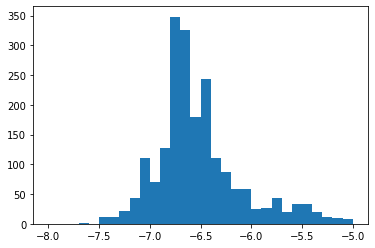

In [61]:
pyplot.hist(Total_from_Dust_Mdot_Data, bins = 30, range = [-8,-5])[0]

In [62]:
def chi_squared_test (m,x):
    if len(m) != len(x):
        print ('Warning: Input arrays of different lengths. Number of predictions does not match number of observations.')
    chi_sq = 0
    i = 0
    while i<len(m):
        if m[i] !=0:
            chi_sq = chi_sq + ((x[i]-m[i])**2)/m[i]
            i += 1
        else:
            i += 1
    return chi_sq

In [63]:
def Numeric_b (MdotObsvData_input,LData_input, MData_input, itterations, guess_b, histogram_bins, histogram_range ): # takes a input arrays of observed data, a number of itterations, and an initial guess for the correct value of b
    Current_b = guess_b
    i = 0
    ObservedCounts = pyplot.hist(MdotObsvData_input, bins = histogram_bins, range = histogram_range)[0]
    Delta = 0.5 # An value to adjust b by. As we get closer to the true value, this will be adjusted to be smaller.
    while i < itterations: # Repeat this calculation for as many times specified to try to find the correct value of b
        pyplot.clf()
        CalculatedMdotArray = CalculateMdotWillsonMethod_single_b (Current_b, LData_input, MData_input) # Make a prediction of what mass loss rates each star will have
        CalculatedMdotArray_b_up = CalculateMdotWillsonMethod_single_b (Current_b+Delta*Current_b, LData_input, MData_input) # Repeat the above step with b = b+Delta*b
        CalculatedMdotArray_b_down = CalculateMdotWillsonMethod_single_b (Current_b-Delta*Current_b, LData_input, MData_input) # Repeat the above step with b = b-Delta*b
        Calculated_Counts = pyplot.hist (CalculatedMdotArray, bins = histogram_bins, range=histogram_range)[0] # Bin mass loss rates from b to create a prediction for how many stars will be in each bin
        Calculated_Counts_b_up = pyplot.hist (CalculatedMdotArray_b_up, bins = histogram_bins, range=histogram_range)[0] # Bin mass loss rates from b+Delta*b to create a prediction for how many stars will be in each bin
        Calcualted_Counts_b_down = pyplot.hist (CalculatedMdotArray_b_down, bins = histogram_bins, range=histogram_range)[0] # Bin mass loss rates from b-Delta*b to create a prediction for how many stars will be in each bin
        #print(Calcualted_Counts_b_down)
        chi_sq_b = chi_squared_test(Calculated_Counts,ObservedCounts) # Perform a Chi^2 test on the current value of b
        chi_sq_b_up = chi_squared_test(Calculated_Counts_b_up,ObservedCounts) # Perform a Chi^2 test on b+Delta*b
        chi_sq_b_down = chi_squared_test(Calcualted_Counts_b_down,ObservedCounts) # Perform a Chi^2 test on b-Delta*b
        #print (chi_sq_b, chi_sq_b_up, chi_sq_b_down)
        if chi_sq_b_up < chi_sq_b: # If a larger b is a better fit...
            Current_b = Current_b + Delta*Current_b # Adjust b to be b(1+Delta)
        elif chi_sq_b_down < chi_sq_b: # If a smaller b is a better fit...
            Current_b = Current_b - Delta*Current_b # Adjust b to be b(1-Delta)
        else: # If the current b is the best fit...
            Delta = 0.9*Delta # Decrease the size of Delta so we are more precise
        i += 1 # Restart the loop with the changes we just made
    print('Current chi^2 values: b:',chi_sq_b,'b+delta*b',chi_sq_b_up,'b-delta*b',chi_sq_b_down)
    return Current_b

In [64]:
#Numeric_b (Total_from_Dust_Mdot_Data,LData,MData,200,7, 30, [-8,-5])

In [65]:
TotalAdjust = 3*10**3 # This values sets the ratio between the total and dust mass loss rates
# We'll translate between Mdot_dust and Mdot using van Loon 2000 results. In that paper, this takes the form (after some manipulation)
# log Mdot = a log z +2 log Mdot_dust + C
# We have to account for differences between Carbon and other type AGB stars (mostly M). That comes in as different values of a
# (different coefficients) and potentially different values for C. log z is determined by the target. For the LMC, 
# log z = -0.45 +- 0.15. For Carbon stars, a= 1+-0.3. For other stars, a=0.7^+0.6_-0.3.
# To first order, the error is (+0.24,-0.375) +DeltaC for non-C stars and (+-0.285)+DeltaC for C stars
Cm = 3.0 # Set a value for the constant in AGB star Mdot weights. This is found by fitting to distribution.

def Dust_to_Total_Mdot(mdot_array,constant_adjust): # Takes the input Mdot_dust and converts to logMdot
    i = 0
    total_mdot_array = [] # an empty list to hold modified data
    while i<len(mdot_array):
        GaslogMdot = np.log10(mdot_array[i])-0.7*(np.log10(0.003/0.0124))+constant_adjust
        TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
        total_mdot_array.append(TotallogMdot)
        i = i + 1 # Increment index
    return np.asarray(total_mdot_array)

Dust_to_Total_Mdot(DustMdotData,2)

array([-7.64270506, -7.64270506, -6.33653542, ..., -6.98720075,
       -7.94373505, -8.33653542])

In [66]:
def Numeric_b_and_total_from_dust (MdotDustData_input,LData_input, MData_input, itterations_b, itterations_total_from_dust, guess_b, guess_Cm, histogram_bins, histogram_range ): # takes a input arrays of observed data, a number of itterations, and an initial guess for the correct value of b
    Current_Cm = guess_Cm
    i_total_mdot = 0
    Delta_Cm = 0.1 # An value to adjust Cm by. As we get closer to the true value, this will be adjusted to be smaller.
    while i_total_mdot < itterations_total_from_dust:
        ObservedCounts = pyplot.hist(Dust_to_Total_Mdot(MdotDustData_input,Current_Cm), bins = histogram_bins, range = histogram_range)[0]
        ObservedCounts_Cm_up = pyplot.hist(Dust_to_Total_Mdot(MdotDustData_input,Current_Cm*(1+Delta_Cm)), bins = histogram_bins, range = histogram_range)[0]
        ObservedCounts_Cm_down = pyplot.hist(Dust_to_Total_Mdot(MdotDustData_input,Current_Cm*(1-Delta_Cm)), bins = histogram_bins, range = histogram_range)[0]
        i_b = 0
        Current_b = guess_b
        Delta = 0.5 # An value to adjust b by. As we get closer to the true value, this will be adjusted to be smaller.
        while i_b < itterations_b: # Repeat this calculation for as many times specified to try to find the correct value of b
            pyplot.clf()
            CalculatedMdotArray = CalculateMdotWillsonMethod_single_b (Current_b, LData_input, MData_input) # Make a prediction of what mass loss rates each star will have
            CalculatedMdotArray_b_up = CalculateMdotWillsonMethod_single_b (Current_b+Delta*Current_b, LData_input, MData_input) # Repeat the above step with b = b+Delta*b
            CalculatedMdotArray_b_down = CalculateMdotWillsonMethod_single_b (Current_b-Delta*Current_b, LData_input, MData_input) # Repeat the above step with b = b-Delta*b
            Calculated_Counts = pyplot.hist (CalculatedMdotArray, bins = histogram_bins, range=histogram_range)[0] # Bin mass loss rates from b to create a prediction for how many stars will be in each bin
            Calculated_Counts_b_up = pyplot.hist (CalculatedMdotArray_b_up, bins = histogram_bins, range=histogram_range)[0] # Bin mass loss rates from b+Delta*b to create a prediction for how many stars will be in each bin
            Calcualted_Counts_b_down = pyplot.hist (CalculatedMdotArray_b_down, bins = histogram_bins, range=histogram_range)[0] # Bin mass loss rates from b-Delta*b to create a prediction for how many stars will be in each bin
            #print(Calcualted_Counts_b_down)
            chi_sq_b = chi_squared_test(Calculated_Counts,ObservedCounts) # Perform a Chi^2 test on the current value of b
            chi_sq_b_up = chi_squared_test(Calculated_Counts_b_up,ObservedCounts) # Perform a Chi^2 test on b+Delta*b
            chi_sq_b_down = chi_squared_test(Calcualted_Counts_b_down,ObservedCounts) # Perform a Chi^2 test on b-Delta*b
            #print (chi_sq_b, chi_sq_b_up, chi_sq_b_down)
            if chi_sq_b_up < chi_sq_b: # If a larger b is a better fit...
                Current_b = Current_b + Delta*Current_b # Adjust b to be b(1+Delta)
            elif chi_sq_b_down < chi_sq_b: # If a smaller b is a better fit...
                Current_b = Current_b - Delta*Current_b # Adjust b to be b(1-Delta)
            else: # If the current b is the best fit...
                Delta = 0.9*Delta # Decrease the size of Delta so we are more precise
            i_b += 1 # Restart the loop with the changes we just made
        returned_b = Current_b 
        chi_sq_b_current_cm = chi_sq_b
        i_b = 0
        Current_b = guess_b
        Delta = 0.5 # An value to adjust b by. As we get closer to the true value, this will be adjusted to be smaller.
        while i_b < itterations_b: # Repeat this calculation for as many times specified to try to find the correct value of b
            pyplot.clf()
            CalculatedMdotArray = CalculateMdotWillsonMethod_single_b (Current_b, LData_input, MData_input) # Make a prediction of what mass loss rates each star will have
            CalculatedMdotArray_b_up = CalculateMdotWillsonMethod_single_b (Current_b+Delta*Current_b, LData_input, MData_input) # Repeat the above step with b = b+Delta*b
            CalculatedMdotArray_b_down = CalculateMdotWillsonMethod_single_b (Current_b-Delta*Current_b, LData_input, MData_input) # Repeat the above step with b = b-Delta*b
            Calculated_Counts = pyplot.hist (CalculatedMdotArray, bins = histogram_bins, range=histogram_range)[0] # Bin mass loss rates from b to create a prediction for how many stars will be in each bin
            Calculated_Counts_b_up = pyplot.hist (CalculatedMdotArray_b_up, bins = histogram_bins, range=histogram_range)[0] # Bin mass loss rates from b+Delta*b to create a prediction for how many stars will be in each bin
            Calcualted_Counts_b_down = pyplot.hist (CalculatedMdotArray_b_down, bins = histogram_bins, range=histogram_range)[0] # Bin mass loss rates from b-Delta*b to create a prediction for how many stars will be in each bin
            #print(Calcualted_Counts_b_down)
            chi_sq_b = chi_squared_test(Calculated_Counts,ObservedCounts_Cm_up) # Perform a Chi^2 test on the current value of b
            chi_sq_b_up = chi_squared_test(Calculated_Counts_b_up,ObservedCounts_Cm_up) # Perform a Chi^2 test on b+Delta*b
            chi_sq_b_down = chi_squared_test(Calcualted_Counts_b_down,ObservedCounts_Cm_up) # Perform a Chi^2 test on b-Delta*b
            #print (chi_sq_b, chi_sq_b_up, chi_sq_b_down)
            if chi_sq_b_up < chi_sq_b: # If a larger b is a better fit...
                Current_b = Current_b + Delta*Current_b # Adjust b to be b(1+Delta)
            elif chi_sq_b_down < chi_sq_b: # If a smaller b is a better fit...
                Current_b = Current_b - Delta*Current_b # Adjust b to be b(1-Delta)
            else: # If the current b is the best fit...
                Delta = 0.9*Delta # Decrease the size of Delta so we are more precise
            i_b += 1 # Restart the loop with the changes we just made
        chi_sq_b_cm_up = chi_sq_b
        i_b = 0
        Current_b = guess_b
        Delta = 0.5 # An value to adjust b by. As we get closer to the true value, this will be adjusted to be smaller.
        while i_b < itterations_b: # Repeat this calculation for as many times specified to try to find the correct value of b
            pyplot.clf()
            CalculatedMdotArray = CalculateMdotWillsonMethod_single_b (Current_b, LData_input, MData_input) # Make a prediction of what mass loss rates each star will have
            CalculatedMdotArray_b_up = CalculateMdotWillsonMethod_single_b (Current_b+Delta*Current_b, LData_input, MData_input) # Repeat the above step with b = b+Delta*b
            CalculatedMdotArray_b_down = CalculateMdotWillsonMethod_single_b (Current_b-Delta*Current_b, LData_input, MData_input) # Repeat the above step with b = b-Delta*b
            Calculated_Counts = pyplot.hist (CalculatedMdotArray, bins = histogram_bins, range=histogram_range)[0] # Bin mass loss rates from b to create a prediction for how many stars will be in each bin
            Calculated_Counts_b_up = pyplot.hist (CalculatedMdotArray_b_up, bins = histogram_bins, range=histogram_range)[0] # Bin mass loss rates from b+Delta*b to create a prediction for how many stars will be in each bin
            Calcualted_Counts_b_down = pyplot.hist (CalculatedMdotArray_b_down, bins = histogram_bins, range=histogram_range)[0] # Bin mass loss rates from b-Delta*b to create a prediction for how many stars will be in each bin
            #print(Calcualted_Counts_b_down)
            chi_sq_b = chi_squared_test(Calculated_Counts,ObservedCounts_Cm_down) # Perform a Chi^2 test on the current value of b
            chi_sq_b_up = chi_squared_test(Calculated_Counts_b_up,ObservedCounts_Cm_down) # Perform a Chi^2 test on b+Delta*b
            chi_sq_b_down = chi_squared_test(Calcualted_Counts_b_down,ObservedCounts_Cm_down) # Perform a Chi^2 test on b-Delta*b
            #print (chi_sq_b, chi_sq_b_up, chi_sq_b_down)
            if chi_sq_b_up < chi_sq_b: # If a larger b is a better fit...
                Current_b = Current_b + Delta*Current_b # Adjust b to be b(1+Delta)
            elif chi_sq_b_down < chi_sq_b: # If a smaller b is a better fit...
                Current_b = Current_b - Delta*Current_b # Adjust b to be b(1-Delta)
            else: # If the current b is the best fit...
                Delta = 0.9*Delta # Decrease the size of Delta so we are more precise
            i_b += 1 # Restart the loop with the changes we just made
        chi_sq_b_cm_down = chi_sq_b
        if chi_sq_b_cm_up < chi_sq_b_current_cm: # If a larger Cm is a better fit...
            Current_Cm = Current_Cm + Delta_Cm*Current_Cm # Adjust Cm to be Cm(1+Delta)
        elif chi_sq_b_cm_down < chi_sq_b_current_cm: # If a smaller Cm is a better fit...
            Current_Cm = Current_Cm - Delta_Cm*Current_Cm # Adjust Cm to be Cm(1-Delta)
        else: # If the current Cm is the best fit...
            Delta_Cm = 0.9*Delta_Cm # Decrease the size of Delta so we are more precise
        i_total_mdot += 1
    #print('Current chi^2 values: b:',chi_sq_b,'b+delta*b',chi_sq_b_up,'b-delta*b',chi_sq_b_down)
    return returned_b, Current_Cm

In [167]:
#Numeric_b_and_total_from_dust (DustMdotData,LData, MData, 50, 50, 8, 2, 30, [-8,-5] )